# Bird Challenge: from BirdNET predictions to observations

**Goal:** label every clip in `birdnet_predictions.csv` with an `observation` when we can be
at least 99 % sure that the BirdNET prediction is correct.

**Method** (Wood & Kahl 2024):
1. Convert BirdNET confidence scores back to the logit scale: `logit = ln(c / (1 - c)) / sensitivity`.
2. For each species, fit a logistic regression `logit(p_correct) = b0 + b1 * logit_score` on the
   ornithologist-validated clips.
3. Solve the fitted curve for `p_correct = 0.99` to get a species-specific score threshold.
4. Every prediction at or above the threshold becomes an observation.

The code lives in the package `src/natural_state/birds/`. This notebook walks through it step by step.
The same pipeline runs from the command line with `uv run birds`.

In [1]:
from pathlib import Path

from natural_state.birds.data import load_predictions, load_validations
from natural_state.birds.observations import label_predictions, summarise
from natural_state.birds.plots import plot_calibration_curves
from natural_state.birds.settings import Settings
from natural_state.birds.thresholds import species_thresholds, thresholds_table

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "birds"

settings = Settings()
settings

Settings(p_target=0.99, sensitivity=1.0, min_validations=50, alpha=0.05, clip=0.0001, prediction_columns=frozenset({'confidence', 'begin_time_s', 'begin_path', 'species_code', 'common_name'}), validation_columns=frozenset({'confidence', 'commonName', 'outcome', 'filename'}))

## 1. Load and check the inputs

Loading fails with a clear message if a column is missing, a confidence lies outside 0–1, or an
outcome is not 0 or 1.

In [2]:
predictions = load_predictions(RAW / "birdnet_predictions.csv", settings)
validations = load_validations(RAW / "validation_results.csv", settings)

print(f"predictions: {len(predictions):,} rows, {predictions['common_name'].nunique()} species")
print(f"validations: {len(validations):,} rows, {validations['commonName'].nunique()} species")

validations.groupby("commonName").agg(
    n=("outcome", "size"),
    correct=("outcome", "sum"),
    min_conf=("confidence", "min"),
    max_conf=("confidence", "max"),
)

predictions: 29,491 rows, 4 species
validations: 551 rows, 4 species


,n,correct,min_conf,max_conf
commonName,,,,
Abyssinian Nightjar,150,117,0.102,1.000
African Black-headed Oriole,150,150,0.104,0.989
Red-billed Firefinch,101,6,0.101,0.907
Three-banded Plover,150,149,0.102,0.994


## 2. Should validations be joined to individual predictions?

The validation filename encodes `<confidence>_<index>_<recording>.wav`. We test whether each
validated clip can be found in the predictions file by species and recording.

In [3]:
val_recording = validations["filename"].str.extract(r"^[\d.]+_\d+_(.+)\.wav$", expand=False)
pred_recording = predictions["begin_path"].str.split("/").str[-1].str.removesuffix(".WAV")
predicted_pairs = set(zip(predictions["common_name"], pred_recording, strict=True))

in_predictions = [
    (species, recording) in predicted_pairs
    for species, recording in zip(validations["commonName"], val_recording, strict=True)
]
match_rate = validations.assign(in_predictions=in_predictions).groupby("commonName")["in_predictions"].mean()
print("share of validated clips whose recording appears in the predictions file:")
print(match_rate.round(2).to_string())

share of validated clips whose recording appears in the predictions file:
commonName
Abyssinian Nightjar            0.92
African Black-headed Oriole    0.21
Red-billed Firefinch           0.32
Three-banded Plover            0.41


Only part of the validated clips come from recordings that are in this predictions export.
Where they do, the 3-decimal confidence in the filename often matches several predictions.
A row-level join would therefore be partial and ambiguous.

**Decision:** treat the validation set as an independent **calibration sample** for each species.
This is what Wood & Kahl intend: validate a random sample of predictions, fit the score–correctness
relationship, and apply it to all predictions. For the platform, validated clips should carry the BirdNET
prediction ID, so that human labels can be stored next to the model-derived observation.

## 3. Per-species thresholds

| Status | When | Threshold rule |
|---|---|---|
| `logistic_fit` | ≥ 50 clips, both outcomes present, slope significantly positive | Solve the logistic curve for p = 0.99 |
| `score_independent` | ≥ 50 clips, but no significant positive slope (incl. all clips correct) | One precision for the species, estimated as (k + 0.5) / (n + 1). If it is ≥ 0.99, accept all predictions within the validated score range. Otherwise accept none. |
| `insufficient_validation` | fewer than 50 clips, or species not validated | No observations. Request validation. |

The pipeline never fails because of one species. It records the status and a reason, and carries on.
A threshold above the highest validated score is an **extrapolation**. It is still applied because
it only makes the rule stricter, but it is flagged for review.

In [4]:
results = species_thresholds(validations, predictions["common_name"], settings)
thresholds = thresholds_table(results)
thresholds.round(4)

,common_name,status,reason,n_validated,n_correct,min_validated_conf,max_validated_conf,beta0,beta1,p_slope,aic,logit_threshold,confidence_threshold,precision_estimate
0,Abyssinian Nightjar,logistic_fit,,150,117,0.102,1.000,3.1590,2.0723,0.0000,79.5903,0.6930,0.6666,NaN
1,African Black-headed Oriole,score_independent,all validated clips correct; precision estimat...,150,150,0.104,0.989,NaN,NaN,NaN,NaN,NaN,0.1040,0.9967
2,Red-billed Firefinch,logistic_fit,threshold above highest validated score (extra...,101,6,0.101,0.907,-1.4578,0.9423,0.0348,45.2027,6.4236,0.9984,NaN
3,Three-banded Plover,score_independent,"slope not significantly positive (b1 = 0.55, p...",150,149,0.102,0.994,5.1703,0.5467,0.4762,15.2314,NaN,0.1020,0.9901


## 4. Visual check of the fitted curves

x-axis: logit-transformed BirdNET score. y-axis: pr(BirdNET prediction is correct).
Points are the validated clips. The dashed line is p = 0.99, and the red line is the
confidence threshold used for the species.

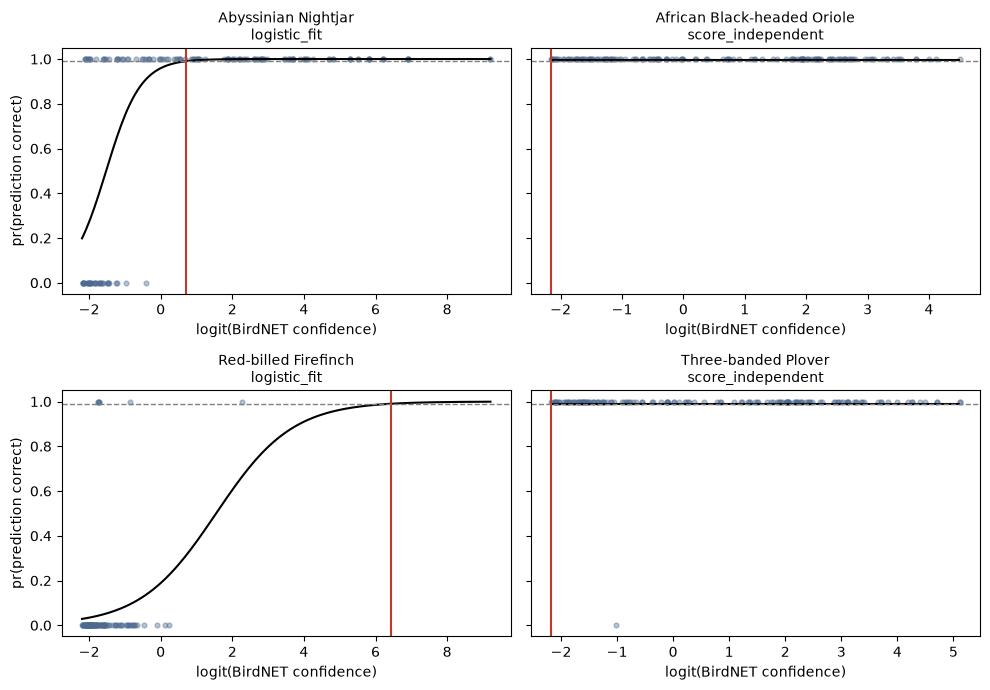

In [5]:
fig = plot_calibration_curves(validations, results, settings)

## 5. Assign observations to all predictions

`observation` holds the species common name when the prediction is accepted, and is empty otherwise.
`p_correct` is the model's probability that the prediction is correct. It is empty where we have no
valid model.

In [6]:
labelled = label_predictions(predictions, thresholds, settings)
summarise(labelled, thresholds)

,predictions,observations,status,confidence_threshold,share_accepted
common_name,,,,,
Abyssinian Nightjar,10187,3147,logistic_fit,0.666638,0.309
African Black-headed Oriole,18054,17646,score_independent,0.104000,0.977
Red-billed Firefinch,235,0,logistic_fit,0.998380,0.000
Three-banded Plover,1015,1001,score_independent,0.102000,0.986


## 6. The output files

`uv run birds` (and `src/natural_state/birds/pipeline.py`) writes three CSVs to `data/output/birds/`.
They are three views of the same result: the rules (species level), the labelled data (prediction level) and an overview.

### `species_thresholds.csv`: the rules (one row per species)

The decision for each species, as produced in section 3.

| Column | Meaning |
|---|---|
| `common_name` | Species. |
| `status` | `logistic_fit`, `score_independent` or `insufficient_validation`. |
| `reason` | Why the status was chosen. It also flags extrapolated thresholds. |
| `n_validated`, `n_correct` | Number of validated clips and how many the ornithologist confirmed. |
| `min_validated_conf`, `max_validated_conf` | Score range covered by the validated clips. |
| `beta0`, `beta1` | Intercept and slope of the logistic fit on the logit score. |
| `p_slope`, `aic` | Significance of the slope and the model's AIC. |
| `logit_threshold` | Logit score where the curve reaches p = 0.99. |
| `confidence_threshold` | The same threshold on the BirdNET confidence scale (0-1). This is the cut-off that is applied. |
| `precision_estimate` | Only for `score_independent`: (k + 0.5) / (n + 1). |

Fields that do not apply to a status are empty. For example, `score_independent` species have no `beta0` or `beta1`.

### `birdnet_predictions_with_observation.csv`: the labelled predictions (one row per prediction)

The original `birdnet_predictions.csv` columns plus three new ones from section 5:

| Column | Meaning |
|---|---|
| `p_correct` | Modelled probability that this prediction is correct. For `score_independent` species it is the same for every prediction of the species. Empty when there is no valid model. |
| `threshold_status` | The species' `status`, repeated per row. |
| `observation` | The species common name if the prediction is accepted (score at or above the threshold), otherwise empty. **This is the column to use downstream.** |

### `observation_summary.csv`: the overview (one row per species)

The summary shown by `summarise()` in section 5.

| Column | Meaning |
|---|---|
| `predictions` | Number of BirdNET predictions for the species. |
| `observations` | How many of them became observations. |
| `status`, `confidence_threshold` | Copied from `species_thresholds.csv`. |
| `share_accepted` | `observations / predictions`. |

The `figures/` subfolder holds the calibration plots from section 4.